# 动态鲁棒定位与 SLAM · 代码展示

保存数据复核与视频展示；默认运行全部不启动仿真。二维使用XY RMSE，三维使用XYZ RMSE；单次理想仿真不构成稳定排名。

<a id="notebook-index"></a>

| 原有场景 | 2D · AMCL | 3D · GICP |
| --- | --- | --- |
| 纯静态 | [查看](#baseline-2d-static) | [查看](#baseline-3d-static) |
| 运动障碍物 | [查看](#baseline-2d-dynamic) | [查看](#baseline-3d-dynamic) |
| 持久结构变化 | [查看](#baseline-2d-large-change) | [查看](#baseline-3d-large-change) |
| 原走廊退化 | [查看](#baseline-2d-corridor) | [查看](#baseline-3d-corridor) |

[四篇原库](#authors) · [原生二维SRRG](#srrg-2d) · [逐条误差复算](#score-recompute) · [走廊持续恢复](#corridor-recovery) · [NDT／GICP早期静态试验](#early-3d) · [末尾：开放问题、假设与简单实验](#hypotheses)


In [1]:
from pathlib import Path
import json, csv, hashlib, subprocess, os
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
from experiment_tools import local_url, videos, package, verify_files, table
from experiment_tools import baseline_scene, probe_scene, refinement_scene, srrg_scene
ROOT = Path.cwd()
DATA = ROOT / 'evidence' if (ROOT / 'evidence').exists() else ROOT.parent.parent / 'results/reference'
ANALYSIS = ROOT / 'analysis/hypotheses' if (ROOT / 'evidence').exists() else ROOT.parent.parent / 'results/analysis/hypotheses'
REPO = Path(os.environ.get('SLAM_DEMO_REPO', r'D:\workspace\be2\slam_learning_updated'))
read = lambda p: json.loads(p.read_text(encoding='utf-8-sig'))
verify_files()

实验包,状态,核对文件,结果
robot-2d-dynamic-matched,executed,66,SHA-256 一致
robot-3d-map-audit,executed,29,SHA-256 一致
srrg-2d-static-graph-merge-on,executed,38,SHA-256 一致
srrg-diagnostic-20261015-025711-mapping-srrg-static-dd423d,diagnostic_failed,27,SHA-256 一致
srrg-diagnostic-20261015-030327-mapping-srrg-static-a275d3,diagnostic_failed,27,SHA-256 一致
srrg-diagnostic-20261015-030729-mapping-srrg-dynamic-14123d,diagnostic_failed,31,SHA-256 一致
srrg-2d-static,executed,69,SHA-256 一致
srrg-2d-dynamic,executed,73,SHA-256 一致
srrg-2d-large-change,executed,130,SHA-256 一致
srrg-2d-corridor,executed,150,SHA-256 一致


共核对 2292 个记录绑定文件；大体积 ROS bag / 点云源文件仍保留在本机原始运行目录。


2292

<a id="authors"></a>

## 1. 原库执行

[↑ 返回目录](#notebook-index)

In [2]:
# dufomap：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-live-dufomap' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-live-dufomap', result=False)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "status": "executed",
  "exit_code": 0,
  "method": "dufomap",
  "command": [
    "/home/qzl/projects/SLAM_Learning/.venv/bin/python",
    "-m",
    "slam_learning.cli",
    "_worker",
    "--root",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202413-author-live-dufomap-2551ae/experiment",
    "--method",
    "dufomap",
    "--output",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202413-author-live-dufomap-2551ae/experiment/results/runs/dufomap-9958d09fff88",
    "--frames",
    "0"
  ],
  "scope": "141 released KITTI-00 scans, pinned author pipeline; paper comparison as native record",
  "metrics": {
    "counts": {
      "kept_static": 16917434,
      "removed_static": 348813,
      "removed_dynamic": 94738,
      "kept_dynamic": 1245
    },
    "SA": 97.97979838930834,
    "DA": 98.70289530437681,
    "AA": 98.34068223458615,
    "HA": 98.3400176268

In [3]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original-live.ps1'), '-Method', 'dufomap']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original-live.ps1 -Method dufomap


In [4]:
# beautymap：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-live-beautymap' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-live-beautymap', result=False)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "status": "executed",
  "exit_code": 0,
  "method": "beautymap",
  "command": [
    "/home/qzl/projects/SLAM_Learning/.venv/bin/python",
    "-m",
    "slam_learning.cli",
    "_worker",
    "--root",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202609-author-live-beautymap-dbdf18/experiment",
    "--method",
    "beautymap",
    "--output",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-202609-author-live-beautymap-dbdf18/experiment/results/runs/beautymap-b9f4a4723ce8",
    "--frames",
    "0"
  ],
  "scope": "141 released KITTI-00 scans, pinned author pipeline; paper comparison as native record",
  "metrics": {
    "counts": {
      "kept_static": 16740135,
      "removed_static": 526112,
      "removed_dynamic": 94388,
      "kept_dynamic": 1595
    },
    "SA": 96.95294524629469,
    "DA": 98.33824739797673,
    "AA": 97.64313962379855,
    "HA": 97.

In [5]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original-live.ps1'), '-Method', 'beautymap']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original-live.ps1 -Method beautymap


In [6]:
# ir-mcl：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-live-ir-mcl' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-live-ir-mcl', result=False)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "status": "executed",
  "exit_code": 0,
  "method": "ir-mcl",
  "command": [
    "/home/qzl/.venvs/ir-mcl/bin/python",
    "-u",
    "main.py",
    "--config_file",
    "./config/global_localization/loc_config_test1.yml"
  ],
  "scope": "released Bonn IPBLab sequence; native config and 100000 initial particles; fresh inference",
  "metrics": {
    "location_rmse_cm": 5.31,
    "yaw_rmse_deg": 1.07,
    "location_lt5_pct": 63.29,
    "location_lt10_pct": 96.09,
    "location_lt20_pct": 100.0,
    "yaw_lt0_5_pct": 47.34,
    "yaw_lt1_pct": 74.37,
    "yaw_lt2_pct": 93.5,
    "scored_poses": 1354
  },
  "source_run": "D:\\workspace\\be2\\slam_learning_updated\\results\\runs\\presentation\\20261014-201724-author-live-ir-mcl-ec568b",
  "live_state": {
    "enabled": true,
    "scope": "Actual RViz+terminal capture during new author execution; read-only current state, display thinning; observer overhead included"
  },
  "timing": {


In [7]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original-live.ps1'), '-Method', 'ir-mcl']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original-live.ps1 -Method ir-mcl


In [8]:
# adam-mcl：查看本次执行记录、命令和视频
record = read(DATA / 'desktop-adam-mcl' / 'record.json')
print(json.dumps({k:v for k,v in record.items() if k != 'artifacts'}, ensure_ascii=False, indent=2)[:7000])
videos('desktop-adam-mcl', result=True)

{
  "schema_version": 1,
  "kind": "author_desktop_demo",
  "method": "adam-mcl",
  "status": "executed",
  "exit_code": 0,
  "command": [
    "/home/qzl/.venvs/adam-mcl/bin/python",
    "-u",
    "repro/live_eval.py",
    "--python",
    "/home/qzl/.venvs/adam-mcl/bin/python",
    "--subdataset",
    "0",
    "--particles",
    "200",
    "--model",
    "/mnt/d/workspace/be2/tmp/repro/AdaM_MCL/Trained_models/simulation_2_2026-10-14 07:52:21.602839/model_train_38epochs.pth",
    "--trials",
    "1",
    "--log",
    "/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-173656-author-adam-mcl-f2821e/native-output.log"
  ],
  "scope": "author code; authored 128-cell surrogate; existing 2432-step checkpoint; fresh 123-update x 1-trial inference; no paper numeric comparison",
  "result_scope": "One fresh trial, saved upstream particle images and native errors, replayed using measured update durations; checkpoint/data surrogate disclosed",
  "metrics": {
    "positi

In [9]:
# 重新执行原库：需要时改为 True；Run All 默认只核对保存证据
RUN_LIVE = False
command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
           str(REPO / 'demo' / 'original.ps1'), '-Method', 'adam-mcl']
print(subprocess.list2cmdline(command))
if RUN_LIVE:
    subprocess.Popen(command)

powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\original.ps1 -Method adam-mcl


## 2. 地图清理计数复算

In [10]:
for name in ('desktop-live-dufomap', 'desktop-live-beautymap'):
    metrics = read(DATA / name / 'metrics.json')
    counts = metrics['counts']
    sa = 100 * counts['kept_static'] / (counts['kept_static'] + counts['removed_static'])
    da = 100 * counts['removed_dynamic'] / (counts['kept_dynamic'] + counts['removed_dynamic'])
    print(name, 'SA', sa, 'DA', da, 'HA', 2*sa*da/(sa+da))
    print(counts, 'threshold_m=', metrics['threshold_m'])

desktop-live-dufomap SA 97.97979838930834 DA 98.70289530437681 HA 98.34001762682132
{'kept_static': 16917434, 'removed_static': 348813, 'removed_dynamic': 94738, 'kept_dynamic': 1245} threshold_m= 0.05
desktop-live-beautymap SA 96.95294524629469 DA 98.33824739797673 HA 97.6406829872703
{'kept_static': 16740135, 'removed_static': 526112, 'removed_dynamic': 94388, 'kept_dynamic': 1595} threshold_m= 0.05


## 3. IR-MCL 原生轨迹复算

N= 1354 RMSE cm= 5.313356278686989 yaw deg= 1.0741486271450587
{'location_rmse_cm': 5.31, 'yaw_rmse_deg': 1.07, 'location_lt5_pct': 63.29, 'location_lt10_pct': 96.09, 'location_lt20_pct': 100.0, 'yaw_lt0_5_pct': 47.34, 'yaw_lt1_pct': 74.37, 'yaw_lt2_pct': 93.5, 'scored_poses': 1354}


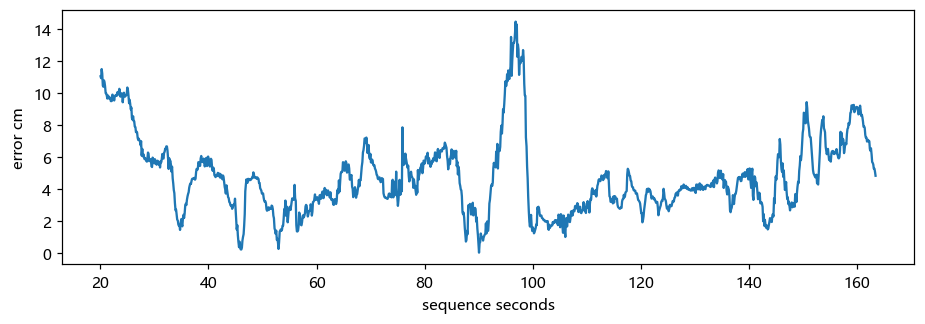

In [11]:
folder = DATA / 'desktop-live-ir-mcl'
gt = np.loadtxt(folder / 'seq_1_gt_pose.txt')
est = np.loadtxt(folder / 'IRMCL.txt')
assert gt.shape == est.shape and np.allclose(gt[:, 0], est[:, 0])
window = gt[:, 0] >= gt[0, 0] + 20
gt, est = gt[window], est[window]
error_cm = np.linalg.norm(est[:, 1:3] - gt[:, 1:3], axis=1) * 100
def yaw(tum):
    x,y,z,w = tum[:,4:8].T
    return np.arctan2(2*(w*z+x*y), 1-2*(y*y+z*z))
delta = yaw(est) - yaw(gt)
error_deg = np.rad2deg(np.arctan2(np.sin(delta), np.cos(delta)))
print('N=', len(gt), 'RMSE cm=', np.sqrt(np.mean(error_cm**2)), 'yaw deg=', np.sqrt(np.mean(error_deg**2)))
print(read(folder / 'metrics.json'))
plt.figure(figsize=(10,3)); plt.plot(gt[:,0], error_cm); plt.ylabel('error cm'); plt.xlabel('sequence seconds'); plt.show()

## 4. 机器人现场：建图 A → 固定地图 → 独立定位 B

In [12]:
# 双击入口只启动本机实时场景；评分读取下方封存数据
SCRIPTS = Path(r'F:\be2演讲\实机脚本')
for path in sorted(SCRIPTS.glob('*.bat')):
    print(path.name)
RUN_LIVE = False
SCRIPT = SCRIPTS / '20-静态_三方法独立RViz实时.bat'
if RUN_LIVE:
    subprocess.Popen(['cmd.exe', '/c', str(SCRIPT)])

00-查看本轮视频.bat
01-静态建图与三维点云.bat
02-动态建图与三维点云.bat
05-走廊点云建图.bat
08-处理最新走廊地图.bat
09-正常停止仿真.bat
10-处理最新静态地图.bat
11-处理最新动态地图.bat
20-静态_三方法独立RViz实时.bat
21-动态_三方法独立RViz实时.bat
22-持久变化_三方法独立RViz实时.bat
23-走廊退化_三方法独立RViz实时.bat
24-自动重录四场景_逐方法实时.bat
31-NDT三维定位_静态.bat
32-GICP三维定位_静态.bat
33-三维静态_三图GICP对照.bat
34-三维动态_三图GICP对照.bat
35-三维持久变化_三图GICP对照.bat
36-三维走廊退化_三图GICP对照.bat
37-三维地图清理结果展示.bat
38-采集假设实验地图A.bat
39-查看假设实验视频.bat
40-2D_静态_假设实验.bat
41-2D_动态_假设实验.bat
42-2D_持久变化_假设实验.bat
43-2D_原走廊退化_假设实验.bat
44-2D_高处标志_派生对照_假设实验.bat
45-3D_静态_假设实验.bat
46-3D_动态_假设实验.bat
47-3D_持久变化_假设实验.bat
48-3D_原走廊退化_假设实验.bat
49-3D_高处标志_派生对照_假设实验.bat
50-自动重录假设实验_二维三维十组.bat
51-2D_原走廊_封存输入细化.bat
52-2D_高处对照_封存输入细化.bat
53-3D_原走廊_封存输入细化.bat
54-3D_高处对照_封存输入细化.bat
55-自动重算四组细化_封存输入.bat
56-查看SRRG二维视频与指标.bat
57-SRRG二维_静态.bat
58-SRRG二维_运动障碍物.bat
59-SRRG二维_持久变化_加载旧图.bat
60-SRRG二维_走廊退化.bat
61-自动录制SRRG二维四场景.bat
论文-adam-mcl.bat
论文-实时-beautymap.bat
论文-实时-dufomap.bat
论文-实时-ir-mcl.bat


In [13]:
# robot-supp-static：真实 Gazebo + RViz + 终端，及采集信息
videos('robot-supp-static', result=False)
print(read(DATA / 'robot-supp-static' / 'runtime.json'))
print(read(DATA / 'robot-supp-static' / 'metrics.json'))

{'world': '/mnt/d/workspace/be2/slam_learning_updated/config/presentation/worlds/S1_static.world', 'spawn': [8.0727, 7.5312, -1.5708], 'scene': 'static', 'world_sha256': '95091c22b2889b350b87487d58ad640094537f665da4b75593a27601803dadba', 'initial_offset': [0.25, 0.15, 0.12], 'scan_restore_after_s': None}
{'kind': 'live_native_ui_session', 'status': 'completed', 'failure': None, 'mode': 'mapping', 'points_received': 537, 'mapping_frames': 54, 'truth_source': 'Gazebo Pose_V named omni_car, top-level simulation timestamp', 'truth_used_for': 'evaluation/display; provided poses only in controlled mapping A', 'score_alignment': 'none; native author-derived maps and truth share world/map coordinates', 'score_sampling': 'native estimator pose updates; nearest truth within 0.05 simulation seconds', 'cases': {}, 'observed_map': {'width': 217, 'height': 143, 'resolution_m': 0.05000000074505806, 'known_cells': 20568}}


In [14]:
# robot-supp-dynamic：真实 Gazebo + RViz + 终端，及采集信息
videos('robot-supp-dynamic', result=False)
print(read(DATA / 'robot-supp-dynamic' / 'runtime.json'))
print(read(DATA / 'robot-supp-dynamic' / 'metrics.json'))

{'world': '/mnt/d/workspace/be2/slam_learning_updated/config/presentation/worlds/S2_dynamic.world', 'spawn': [8.0727, 7.5312, -1.5708], 'scene': 'dynamic', 'world_sha256': '6a5837880254d5647634247be12b6953438f87d5326682bcd2a376b2c6023e53', 'initial_offset': [0.25, 0.15, 0.12], 'scan_restore_after_s': None}
{'kind': 'live_native_ui_session', 'status': 'completed', 'failure': None, 'mode': 'mapping', 'points_received': 546, 'mapping_frames': 55, 'truth_source': 'Gazebo Pose_V named omni_car, top-level simulation timestamp', 'truth_used_for': 'evaluation/display; provided poses only in controlled mapping A', 'score_alignment': 'none; native author-derived maps and truth share world/map coordinates', 'score_sampling': 'native estimator pose updates; nearest truth within 0.05 simulation seconds', 'cases': {}, 'observed_map': {'width': 244, 'height': 143, 'resolution_m': 0.05000000074505806, 'known_cells': 20509}}


In [15]:
# robot-corridor-v2-mapping：真实 Gazebo + RViz + 终端，及采集信息
videos('robot-corridor-v2-mapping', result=False)
print(read(DATA / 'robot-corridor-v2-mapping' / 'runtime.json'))
print(read(DATA / 'robot-corridor-v2-mapping' / 'metrics.json'))

{'world': '/mnt/d/workspace/be2/slam_learning_updated/config/presentation/worlds/S4_degradation.world', 'spawn': [7.15, -3.1, 0.0], 'scene': 'corridor', 'world_sha256': 'e57fee1a83aa2b32b71d5ff4b19cdfed4cfae3d8330e12cc67ec4e807512bc6b', 'initial_offset': [1.0, 0.15, 0.12], 'scan_restore_after_s': 50.0}
{'kind': 'live_native_ui_session', 'status': 'completed', 'failure': None, 'mode': 'mapping', 'points_received': 744, 'mapping_frames': 75, 'truth_source': 'Gazebo Pose_V named omni_car, top-level simulation timestamp', 'truth_used_for': 'evaluation/display; provided poses only in controlled mapping A', 'score_alignment': 'none; native author-derived maps and truth share world/map coordinates', 'score_sampling': 'AMCL pose updates; nearest truth within 0.05 simulation seconds', 'cases': {}, 'observed_map': {'width': 482, 'height': 111, 'resolution_m': 0.05000000074505806, 'known_cells': 31115}}


<a id="srrg-2d"></a>

## 5. 原生二维 SRRG 建图

[↑ 返回目录](#notebook-index)

论文用连续二维扫描和里程计维护动态环境地图，在 LCAS–STRANDS／MIT Stata Center 长期、多会话记录中测试。本次是同四类环境的短路线适用性测试，不宣称完成长期论文复现。灰色为按各帧估计累计的原始点，蓝色为作者维护图；不以真值配准。

[纯静态](#srrg-static) · [运动障碍物](#srrg-dynamic) · [持久变化](#srrg-large-change) · [走廊退化](#srrg-corridor) · [失败诊断](#srrg-failures)

主组关闭作者默认关闭的图合并，保留局部动态点融合。持久变化组加载静态A旧图，执行多会话更新；变化只增加结构，动态删除率为N/A。

退化输入保留原720角度格，其中72束为实测值、其余无效，3.5m有效距离，录制后50仿真秒恢复。直接72项数组被作者入口拒绝，不能悄悄补点。旧固定地图实验只能给出定位异常时间，不能当作建图故障时间。


<a id="srrg-static"></a>

### 纯静态 · 原生二维

[↑ 返回目录](#notebook-index)

In [16]:
srrg_scene('static')

方法,地图类型,指标效果
Raw,原生二维点图,动态残影删除 N/A；静态覆盖保留 100.00%
srrg_mapper2d,原生二维点图,动态残影删除 N/A；静态覆盖保留 99.84%


10cm观测支持、15cm覆盖容差；只评价后续实测射线验证为空的动态残影。端到端地图维护指标，不能与3D精确点删除率直接排名。

建图轨迹XY RMSE cm: 0.7070869107428702
事件: []


<a id="srrg-dynamic"></a>

### 运动障碍物 · 原生二维

[↑ 返回目录](#notebook-index)

In [17]:
srrg_scene('dynamic')

方法,地图类型,指标效果
Raw,原生二维点图,动态残影删除 0.00%；静态覆盖保留 100.00%
srrg_mapper2d,原生二维点图,动态残影删除 42.31%；静态覆盖保留 99.51%


10cm观测支持、15cm覆盖容差；只评价后续实测射线验证为空的动态残影。端到端地图维护指标，不能与3D精确点删除率直接排名。

建图轨迹XY RMSE cm: 0.6352424666044589
事件: []


<a id="srrg-large-change"></a>

### 持久结构变化 · 原生二维

[↑ 返回目录](#notebook-index)

In [18]:
srrg_scene('large-change')

方法,地图类型,指标效果
Raw,原生二维点图,动态残影删除 N/A；静态覆盖保留 100.00%
srrg_mapper2d,原生二维点图,动态残影删除 N/A；静态覆盖保留 99.71%


10cm观测支持、15cm覆盖容差；只评价后续实测射线验证为空的动态残影。端到端地图维护指标，不能与3D精确点删除率直接排名。

建图轨迹XY RMSE cm: 0.4626750388373366
事件: []


<a id="srrg-corridor"></a>

### 原走廊退化 · 原生二维

[↑ 返回目录](#notebook-index)

In [19]:
srrg_scene('corridor')

方法,地图类型,指标效果
Raw,原生二维点图,动态残影删除 N/A；静态覆盖保留 83.43%
srrg_mapper2d,原生二维点图,动态残影删除 N/A；静态覆盖保留 82.24%


10cm观测支持、15cm覆盖容差；只评价后续实测射线验证为空的动态残影。端到端地图维护指标，不能与3D精确点删除率直接排名。

建图轨迹XY RMSE cm: 83.2268104338166
事件: [{'kind': 'native_mapper_reset', 'criterion': 'BadCorrespondences: native tracker map reset', 'stamp_s': 11.1, 'recording_sim_elapsed_s': 3.5999999999999996, 'approx_mp4_s': 4.552714109420776}, {'kind': 'observation_change', 'criterion': 'limited', 'stamp_s': 7.5, 'recording_sim_elapsed_s': 0.0, 'approx_mp4_s': 2.7234017848968506}, {'kind': 'observation_change', 'criterion': 'full', 'stamp_s': 57.6, 'recording_sim_elapsed_s': 50.1, 'approx_mp4_s': 50.880186319351196}, {'kind': 'pose_error_warning', 'criterion': 'XY error >0.2m sustained >=2.8s, independent truth, not a map-failure label', 'stamp_s': 11.5, 'recording_sim_elapsed_s': 4.0, 'approx_mp4_s': 4.9607038497924805}]


<a id="srrg-failures"></a>

### SRRG 失败与额外对照（保留）

前两次是联调错误：Eigen ABI不同和stdout诊断污染传输，均已修复。图合并开启的动态组在最后成功输出仿真66.0s／录制55.4s后出现g2o数值分解失败；关闭图合并的独立新会话完整结束。这提示图维护／数值兼容问题，独立会话本身不足以证明单一因果，也不能据此否定论文。额外静态图合并开启组可运行。


In [20]:
for name in ('srrg-diagnostic-20261015-025711-mapping-srrg-static-dd423d',
             'srrg-diagnostic-20261015-030327-mapping-srrg-static-a275d3',
             'srrg-diagnostic-20261015-030729-mapping-srrg-dynamic-14123d',
             'srrg-2d-static-graph-merge-on'):
    print(name, read(DATA/name/'record.json')['status'])
    videos(name, result=False)

srrg-diagnostic-20261015-025711-mapping-srrg-static-dd423d diagnostic_failed


srrg-diagnostic-20261015-030327-mapping-srrg-static-a275d3 diagnostic_failed


srrg-diagnostic-20261015-030729-mapping-srrg-dynamic-14123d diagnostic_failed


srrg-2d-static-graph-merge-on executed


## 5b. 保留的三维清理图二维投影：每种地图的现场执行与保存结果

<a id="baseline-2d-static"></a>

### 纯静态 · 2D

[↑ 返回目录](#notebook-index)

In [21]:
# 三列表格先于视频；从CSV复算XY，走廊使用受限观测组。
baseline_scene('robot-live-static', '2d', prefix='')

方法,地图类型,指标效果
Raw,原始二维投影图,动态格删除 N/A；静态格保留 100.00%
DUFOMap,去动态点二维投影图,动态格删除 N/A；静态格保留 100.00%
BeautyMap,离线清理二维投影图,动态格删除 N/A；静态格保留 96.51%


方法,独立下游定位指标
raw,XY RMSE 7.28cm
dufomap,XY RMSE 7.28cm
beautymap,XY RMSE 6.89cm


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="baseline-2d-dynamic"></a>

### 运动障碍物 · 2D

[↑ 返回目录](#notebook-index)

In [22]:
# 三列表格先于视频；从CSV复算XY，走廊使用受限观测组。
baseline_scene('robot-2d-dynamic-matched', '2d', prefix='')

方法,地图类型,指标效果
Raw,原始二维投影图,动态格删除 0.00%；静态格保留 100.00%
DUFOMap,去动态点二维投影图,动态格删除 8.33%；静态格保留 100.00%
BeautyMap,离线清理二维投影图,动态格删除 33.33%；静态格保留 96.64%


方法,独立下游定位指标
raw,XY RMSE 7.52cm
dufomap,XY RMSE 8.19cm
beautymap,XY RMSE 7.29cm


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="baseline-2d-large-change"></a>

### 持久结构变化 · 2D

[↑ 返回目录](#notebook-index)

In [23]:
# 三列表格先于视频；从CSV复算XY，走廊使用受限观测组。
baseline_scene('robot-live-large-change', '2d', prefix='')

方法,地图类型,指标效果
Raw,原始二维投影图,动态格删除 N/A；静态格保留 100.00%（静态A旧图；未更新B）
DUFOMap,去动态点二维投影图,动态格删除 N/A；静态格保留 100.00%（静态A旧图；未更新B）
BeautyMap,离线清理二维投影图,动态格删除 N/A；静态格保留 96.51%（静态A旧图；未更新B）


方法,独立下游定位指标
raw,XY RMSE 6.84cm
dufomap,XY RMSE 6.84cm
beautymap,XY RMSE 6.39cm


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="baseline-2d-corridor"></a>

### 原走廊退化 · 2D

[↑ 返回目录](#notebook-index)

In [24]:
# 三列表格先于视频；从CSV复算XY，走廊使用受限观测组。
baseline_scene('robot-corridor-v2', '2d', prefix='degraded_')

方法,地图类型,指标效果
Raw,原始二维投影图,动态格删除 N/A；静态格保留 100.00%
DUFOMap,去动态点二维投影图,动态格删除 N/A；静态格保留 100.00%
BeautyMap,离线清理二维投影图,动态格删除 N/A；静态格保留 100.00%


方法,独立下游定位指标
raw,XY RMSE 72.53cm；恢复后13.3s持续收敛
dufomap,XY RMSE 72.53cm；恢复后13.3s持续收敛
beautymap,XY RMSE 72.53cm；恢复后13.3s持续收敛


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="score-recompute"></a>

## 6. 实测误差：逐条时间关联与 RMSE

[↑ 返回目录](#notebook-index)

In [25]:
# e_i = hypot(estimate_x-truth_x, estimate_y-truth_y)
# RMSE = sqrt(mean(e_i**2)); yaw = atan2(sin(delta),cos(delta))
# 包含初始化；不拟合坐标；匹配上限 0.05 仿真秒。
for name in ('robot-live-static','robot-2d-dynamic-matched','robot-live-large-change','robot-corridor-v2'):
    folder = DATA / name
    truth = [json.loads(line) for line in (folder/'truth.jsonl').read_text().splitlines()]
    stamps = np.array([row['stamp_s'] for row in truth])
    for path in sorted(folder.glob('*-samples.csv')):
        rows = list(csv.DictReader(path.open(encoding='utf-8')))
        arr = {key:np.array([float(row[key]) for row in rows]) for key in rows[0]}
        xy = np.hypot(arr['estimate_x']-arr['truth_x'], arr['estimate_y']-arr['truth_y'])
        angle = arr['estimate_yaw']-arr['truth_yaw']
        angle = np.arctan2(np.sin(angle), np.cos(angle))
        assert np.allclose(xy,arr['position_error_m'])
        assert np.allclose(angle,arr['yaw_error_rad'])
        for i,stamp in enumerate(arr['stamp_s']):
            near = int(np.argmin(abs(stamps-stamp)))
            assert abs(stamps[near]-stamp) <= .05 + 1e-9
            assert np.allclose(truth[near]['xyz'][:2], [arr['truth_x'][i],arr['truth_y'][i]])
        print(name, path.stem, 'N=',len(rows), 'RMSE cm=', np.sqrt(np.mean(xy**2))*100,
              'yaw deg=', np.rad2deg(np.sqrt(np.mean(angle**2))))

robot-live-static beautymap-samples N= 290 RMSE cm= 6.890830689932812 yaw deg= 1.048481029710238
robot-live-static dufomap-samples N= 290 RMSE cm= 7.2797356048237285 yaw deg= 1.034383191048404
robot-live-static raw-samples N= 290 RMSE cm= 7.279735604823724 yaw deg= 1.0343831910484043
robot-2d-dynamic-matched beautymap-samples N= 291 RMSE cm= 7.294859001824294 yaw deg= 1.7933681393576375
robot-2d-dynamic-matched clean_beautymap-samples N= 291 RMSE cm= 7.298884529340377 yaw deg= 1.8051178598671438
robot-2d-dynamic-matched clean_dufomap-samples N= 291 RMSE cm= 7.9323285832954715 yaw deg= 1.7475063281895569
robot-2d-dynamic-matched clean_raw-samples N= 291 RMSE cm= 7.7014422235481454 yaw deg= 1.8008392716185073
robot-2d-dynamic-matched dufomap-samples N= 291 RMSE cm= 8.186796407189753 yaw deg= 1.7617300348448262
robot-2d-dynamic-matched raw-samples N= 291 RMSE cm= 7.519897011405143 yaw deg= 1.776054667799004
robot-live-large-change beautymap-samples N= 290 RMSE cm= 6.3853469392372215 yaw d

robot-corridor-v2 degraded_raw-samples N= 508 RMSE cm= 72.52638342027143 yaw deg= 0.8545970026150744
robot-corridor-v2 dufomap-samples N= 508 RMSE cm= 71.6034538089802 yaw deg= 0.8136684104818286
robot-corridor-v2 raw-samples N= 508 RMSE cm= 71.6034538089802 yaw deg= 0.8136684104818286


<a id="corridor-recovery"></a>

## 7. 新走廊：受限 → 恢复 → 持续确认

[↑ 返回目录](#notebook-index)

{
  "raw": {
    "restore_stamp_s": 66.2,
    "criterion": "position <0.1m and absolute yaw <5deg for 5 simulation seconds, >=8 native updates",
    "sustained_convergence_delay_s": 6.599999999999994,
    "converged": true,
    "scope": "recovery of an offset initial belief when full observations return; no physical kidnapping"
  },
  "dufomap": {
    "restore_stamp_s": 66.2,
    "criterion": "position <0.1m and absolute yaw <5deg for 5 simulation seconds, >=8 native updates",
    "sustained_convergence_delay_s": 6.599999999999994,
    "converged": true,
    "scope": "recovery of an offset initial belief when full observations return; no physical kidnapping"
  },
  "beautymap": {
    "restore_stamp_s": 66.2,
    "criterion": "position <0.1m and absolute yaw <5deg for 5 simulation seconds, >=8 native updates",
    "sustained_convergence_delay_s": 6.599999999999994,
    "converged": true,
    "scope": "recovery of an offset initial belief when full observations return; no physical kidnap

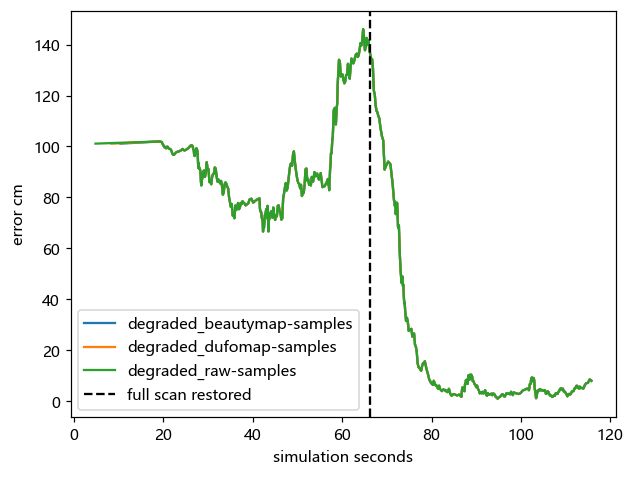

In [26]:
folder = DATA / 'robot-corridor-v2'
record = read(folder/'record.json')
print(json.dumps(record['restoration'], indent=2))
events = [json.loads(line) for line in (folder/'scan-stress.jsonl').read_text().splitlines()]
restore = min(row['stamp_s'] for row in events if row['phase']=='restored')
for path in sorted(folder.glob('degraded_*-samples.csv')):
    rows = list(csv.DictReader(path.open()))
    t=np.array([float(row['stamp_s']) for row in rows])
    e=np.array([float(row['position_error_m']) for row in rows])
    plt.plot(t,e*100,label=path.stem)
plt.axvline(restore,color='black',linestyle='--',label='full scan restored')
plt.xlabel('simulation seconds'); plt.ylabel('error cm'); plt.legend(); plt.show()

<a id="early-3d"></a>

## 8. 早期三维固定地图定位：NDT / GICP

[↑ 返回目录](#notebook-index)

In [27]:
for name in ("robot-ndt-static", "robot-gicp-static"):
    videos(name)
    folder = DATA / name
    print(read(folder / "cases.json"))
    print(read(folder / "metrics.json")["cases"])
    for path in folder.glob("*-samples.csv"):
        rows = list(csv.DictReader(path.open()))
        error = np.array([np.hypot(float(r["estimate_x"])-float(r["truth_x"]),
                                    float(r["estimate_y"])-float(r["truth_y"])) for r in rows])
        print(name, len(error), np.sqrt(np.mean(error**2))*100, "cm")
# 同参数两轮都保留；差异原因待查，不挑选好看的结果。
print("NDT initial trial:", read(DATA / "robot-ndt-static-initial" / "metrics.json")["cases"])
print("NDT latest trial:", read(DATA / "robot-ndt-static" / "metrics.json")["cases"])

{'ndt': {'method': 'raw', 'map_yaml': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw/map.yaml', 'mapping_scene': 'static', 'initial_pose': {'x': 8.3227, 'y': 7.6812000000000005, 'z': 0.0, 'yaw': -1.4508}, 'localizer': 'NDT_OMP', 'map_pcd': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw-map.pcd', 'pose_topic': '/ndt/pcl_pose', 'native_map_odom_tf': True}}
{'ndt': {'samples': 402, 'dropped_unsynchronized': 1, 'position_rmse_m': 0.009270215223387042, 'yaw_rmse_deg': 0.17128034574914214, 'post_warmup_5s_samples': 361, 'post_warmup_5s_position_rmse_m': 0.009286064072528808, 'position_p95_m': 0.015813883735064014}}
robot-ndt-static 402 0.9270215223387042 cm


{'gicp': {'method': 'raw', 'map_yaml': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw/map.yaml', 'mapping_scene': 'static', 'initial_pose': {'x': 8.3227, 'y': 7.6812000000000005, 'z': 0.0, 'yaw': -1.4508}, 'localizer': 'GICP', 'map_pcd': '/mnt/d/workspace/be2/slam_learning_updated/results/runs/presentation/20261014-163140-mapping-static-24597a/author-maps-20261014-165909/raw-map.pcd', 'pose_topic': '/gicp/pcl_pose', 'native_map_odom_tf': True}}
{'gicp': {'samples': 397, 'dropped_unsynchronized': 1, 'position_rmse_m': 0.010910893890758328, 'yaw_rmse_deg': 0.1601187858899252, 'post_warmup_5s_samples': 368, 'post_warmup_5s_position_rmse_m': 0.011047977871584297, 'position_p95_m': 0.014853403815938799}}
robot-gicp-static 397 1.0910893890758329 cm
NDT initial trial: {'ndt': {'samples': 399, 'dropped_unsynchronized': 1, 'position_rmse_m': 0.34426276970654224, 'yaw_rmse_deg': 0.14846594120325204, 'pos

## 9. 三维：Raw／DUFOMap／BeautyMap共用GICP

三维输入不是完整三维SLAM：地图A使用给定位姿，定位B使用独立观测。

<a id="baseline-3d-static"></a>

### 纯静态 · 3D

[↑ 返回目录](#notebook-index)

In [28]:
# 同一三维GICP，只改变地图；从完整位姿CSV复算XYZ。
baseline_scene('robot-3d-static', '3d')

方法,地图类型,指标效果
Raw,原始三维点云图,动态点删除 N/A；静态点保留 100.00%
DUFOMap,去动态点三维点云图,动态点删除 N/A；静态点保留 100.00%
BeautyMap,离线清理三维点云图,动态点删除 N/A；静态点保留 83.33%


方法,独立下游定位指标
raw,XYZ RMSE 0.95cm
dufomap,XYZ RMSE 0.99cm
beautymap,XYZ RMSE 1.07cm


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="baseline-3d-dynamic"></a>

### 运动障碍物 · 3D

[↑ 返回目录](#notebook-index)

In [29]:
# 同一三维GICP，只改变地图；从完整位姿CSV复算XYZ。
baseline_scene('robot-3d-dynamic', '3d')

方法,地图类型,指标效果
Raw,原始三维点云图,动态点删除 0.00%；静态点保留 100.00%
DUFOMap,去动态点三维点云图,动态点删除 46.59%；静态点保留 100.00%
BeautyMap,离线清理三维点云图,动态点删除 74.36%；静态点保留 81.15%


方法,独立下游定位指标
raw,XYZ RMSE 0.98cm
dufomap,XYZ RMSE 0.98cm
beautymap,XYZ RMSE 1.04cm


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="baseline-3d-large-change"></a>

### 持久结构变化 · 3D

[↑ 返回目录](#notebook-index)

In [30]:
# 同一三维GICP，只改变地图；从完整位姿CSV复算XYZ。
baseline_scene('robot-3d-large-change', '3d')

方法,地图类型,指标效果
Raw,原始三维点云图,动态点删除 N/A；静态点保留 100.00%（静态A旧图；未更新B）
DUFOMap,去动态点三维点云图,动态点删除 N/A；静态点保留 100.00%（静态A旧图；未更新B）
BeautyMap,离线清理三维点云图,动态点删除 N/A；静态点保留 83.33%（静态A旧图；未更新B）


方法,独立下游定位指标
raw,XYZ RMSE 0.93cm
dufomap,XYZ RMSE 1.01cm
beautymap,XYZ RMSE 1.04cm


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="baseline-3d-corridor"></a>

### 原走廊退化 · 3D

[↑ 返回目录](#notebook-index)

In [31]:
# 同一三维GICP，只改变地图；从完整位姿CSV复算XYZ。
baseline_scene('robot-3d-corridor', '3d')

方法,地图类型,指标效果
Raw,原始三维点云图,动态点删除 N/A；静态点保留 100.00%
DUFOMap,去动态点三维点云图,动态点删除 N/A；静态点保留 100.00%
BeautyMap,离线清理三维点云图,动态点删除 N/A；静态点保留 99.90%


方法,独立下游定位指标
raw,XYZ RMSE 474.38cm；恢复后样本不足
dufomap,XYZ RMSE 497.05cm；未持续收敛
beautymap,XYZ RMSE 592.00cm；未持续收敛


地图清理看动态删除与静态保留；二维为5cm唯一格，三维为原点保留。无动态目标记N/A。定位RMSE包含初始化，单轮小差异不排名；缺失定位输出不补零。

<a id="hypotheses"></a>

## 10. 从开放问题提出假设，再做简单实验

[↑ 返回总目录](#notebook-index)

- **H1 Guard**：稳健残差、较小对应门槛、弱方向抑制和里程计正则，检验能否减轻错误匹配。组合实验不能分辨单个组件的贡献。
- **H2 Depth**：真实4m深度相机提供二维切片以外的高度线索；若仍是平行墙，更多点不保证更多定位信息。
- **H3 Search**：有界多位置候选搜索，分数差和连续两次运动一致后接受；接受候选不等于已恢复。

二维定位B移除三维雷达，使用二维雷达＋320×240、水平80°、0.25–4m深度相机；三维组使用16线雷达＋同一相机。五原型同帧同数组；原生AMCL／GICP是同源参照。A给定位姿建图且保留三维雷达参照，B不读取真值，地图冻结。原型估计x/y/yaw，使用A标定高度，roll/pitch固定；不是完整六自由度SLAM，也未验证仅廉价传感器自主建图。

前三场景90仿真秒，走廊120秒；准备期及录屏起始后50仿真秒限制雷达，随后恢复。恢复标准为XY<0.1m、|yaw|<5°连续5s且至少8次更新。没有真实搬动机器人，不是任意全局绑架恢复。

<a id="hypothesis-index"></a>

| 场景 | 2D＋深度 | 3D＋深度 |
| --- | --- | --- |
| 纯静态 | [查看](#hypothesis-2d-static) | [查看](#hypothesis-3d-static) |
| 运动障碍物 | [查看](#hypothesis-2d-dynamic) | [查看](#hypothesis-3d-dynamic) |
| 持久结构变化 | [查看](#hypothesis-2d-large-change) | [查看](#hypothesis-3d-large-change) |
| 原走廊退化 | [查看](#hypothesis-2d-corridor) | [查看](#hypothesis-3d-corridor) |
| 高处几何·派生对照 | [查看](#hypothesis-2d-height-corridor) | [查看](#hypothesis-3d-height-corridor) |

[同输入粗到细补充实验](#refinement-index) · [输入与高度复核](#input-audit) · [有效／无效与原因](#hypothesis-findings)


In [32]:
# 正式重测前冻结协议；首轮z=0错误不再作为主结果。
protocol = read(ANALYSIS / 'calibrated-protocol.json')
print('协议冻结UTC:', protocol['frozen_at_utc'])
print('搜索:', protocol['parameters']['search_translation_radius_m'], 'm /',
      protocol['parameters']['search_yaw_radius_deg'], 'deg')
table(['地图A', '车体高度(m)', '定位B真值用于标定'],
      [[scene, f"{prior['ground_z_m']:.8f}", prior['localization_B_truth_used']]
       for scene, prior in protocol['mapping_A_height_priors'].items()])
print('给定位姿的A用于高度基准，B真值只用于评分；不是实机精度或稳定排名结论。')

协议冻结UTC: 2026-10-14T22:42:09.671514+00:00
搜索: 2.0 m / 30 deg


地图A,车体高度(m),定位B真值用于标定
static,0.09413999,False
dynamic,0.09413999,False
corridor,0.09413999,False
height-corridor,0.09413999,False


给定位姿的A用于高度基准，B真值只用于评分；不是实机精度或稳定排名结论。


### 2D · 假设实验实录

<a id="hypothesis-2d-static"></a>

#### 纯静态 · 2D

[↑ 返回假设实验目录](#hypothesis-index)

In [33]:
# 从保存CSV复算XY；三列表格先于真实窗口视频。
probe_scene('2d', 'static')

方法,地图／观测,指标效果
Raw＋AMCL,同源二维栅格投影图,XY RMSE 6.82cm
Plain ICP,二维雷达点图,XY RMSE 0.15cm
H1 Guard,二维雷达点图,XY RMSE 0.15cm；接近Plain
H2 Guard＋Depth,二维雷达点图＋深度点图,XY RMSE 0.21cm；较Guard高0.06cm
H3 雷达搜索,二维雷达点图,XY RMSE 0.15cm；接近Guard
H3 深度＋搜索,二维雷达点图＋深度点图,XY RMSE 0.21cm；接近Depth


五原型各264帧，有效深度219帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

**原生参照最后输出73.2s，原型至99.4s；其RMSE仅覆盖已有输出。**

<a id="hypothesis-2d-dynamic"></a>

#### 运动障碍物 · 2D

[↑ 返回假设实验目录](#hypothesis-index)

In [34]:
# 从保存CSV复算XY；三列表格先于真实窗口视频。
probe_scene('2d', 'dynamic')

方法,地图／观测,指标效果
Raw＋AMCL,同源二维栅格投影图,XY RMSE 7.08cm
Plain ICP,二维雷达点图,XY RMSE 0.37cm
H1 Guard,二维雷达点图,XY RMSE 0.19cm；较Plain低0.18cm
H2 Guard＋Depth,二维雷达点图＋深度点图,XY RMSE 0.18cm；接近Guard
H3 雷达搜索,二维雷达点图,XY RMSE 0.19cm；接近Guard
H3 深度＋搜索,二维雷达点图＋深度点图,XY RMSE 0.18cm；接近Depth


五原型各265帧，有效深度181帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

**原生参照最后输出72.3s，原型至99.7s；其RMSE仅覆盖已有输出。**

<a id="hypothesis-2d-large-change"></a>

#### 持久结构变化 · 2D

[↑ 返回假设实验目录](#hypothesis-index)

In [35]:
# 从保存CSV复算XY；三列表格先于真实窗口视频。
probe_scene('2d', 'large-change')

方法,地图／观测,指标效果
Raw＋AMCL,同源二维栅格投影图,XY RMSE 6.28cm
Plain ICP,二维雷达点图,XY RMSE 7.98cm
H1 Guard,二维雷达点图,XY RMSE 0.49cm；较Plain低7.49cm
H2 Guard＋Depth,二维雷达点图＋深度点图,XY RMSE 0.49cm；接近Guard
H3 雷达搜索,二维雷达点图,XY RMSE 0.49cm；接近Guard
H3 深度＋搜索,二维雷达点图＋深度点图,XY RMSE 0.49cm；接近Depth


五原型各263帧，有效深度187帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

**原生参照最后输出71.3s，原型至99.3s；其RMSE仅覆盖已有输出。**

<a id="hypothesis-2d-corridor"></a>

#### 原走廊退化 · 2D

[↑ 返回假设实验目录](#hypothesis-index)

In [36]:
# 从保存CSV复算XY；三列表格先于真实窗口视频。
probe_scene('2d', 'corridor')

方法,地图／观测,指标效果
Raw＋AMCL,同源二维栅格投影图,XY RMSE 100.61cm；恢复后45.7s持续收敛
Plain ICP,二维雷达点图,XY RMSE 1037.69cm；未持续收敛
H1 Guard,二维雷达点图,XY RMSE 100.48cm；较Plain低937.21cm；未持续收敛
H2 Guard＋Depth,二维雷达点图＋深度点图,XY RMSE 100.54cm；较Guard高0.06cm；未持续收敛
H3 雷达搜索,二维雷达点图,XY RMSE 70.40cm；较Guard低30.08cm；恢复后5.8s持续收敛
H3 深度＋搜索,二维雷达点图＋深度点图,XY RMSE 70.44cm；较Depth低30.11cm；恢复后5.8s持续收敛


五原型各338帧，有效深度195帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

<a id="hypothesis-2d-height-corridor"></a>

#### 高处几何·派生对照 · 2D

[↑ 返回假设实验目录](#hypothesis-index)

此场景额外加入两块高处几何，是单独的结构互补可行性对照，不能冒充原走廊结果。

In [37]:
# 从保存CSV复算XY；三列表格先于真实窗口视频。
probe_scene('2d', 'height-corridor')

方法,地图／观测,指标效果
Raw＋AMCL,同源二维栅格投影图,XY RMSE 67.00cm；恢复后11.7s持续收敛
Plain ICP,二维雷达点图,XY RMSE 285.54cm；未持续收敛
H1 Guard,二维雷达点图,XY RMSE 101.15cm；较Plain低184.39cm；未持续收敛
H2 Guard＋Depth,二维雷达点图＋深度点图,XY RMSE 100.77cm；较Guard低0.38cm；未持续收敛
H3 雷达搜索,二维雷达点图,XY RMSE 70.93cm；较Guard低30.22cm；恢复后5.0s持续收敛
H3 深度＋搜索,二维雷达点图＋深度点图,XY RMSE 21.15cm；较Depth低79.61cm；恢复后0.2s持续收敛


五原型各345帧，有效深度239帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

### 3D · 假设实验实录

<a id="hypothesis-3d-static"></a>

#### 纯静态 · 3D

[↑ 返回假设实验目录](#hypothesis-index)

In [38]:
# 从保存CSV复算XYZ；三列表格先于真实窗口视频。
probe_scene('3d', 'static')

方法,地图／观测,指标效果
Raw＋GICP,三维雷达点图,XYZ RMSE 1.08cm
Plain ICP,三维雷达点图,XYZ RMSE 0.12cm
H1 Guard,三维雷达点图,XYZ RMSE 0.12cm；接近Plain
H2 Guard＋Depth,三维雷达点图＋深度点图,XYZ RMSE 0.21cm；较Guard高0.09cm
H3 雷达搜索,三维雷达点图,XYZ RMSE 0.12cm；接近Guard
H3 深度＋搜索,三维雷达点图＋深度点图,XYZ RMSE 0.21cm；接近Depth


五原型各266帧，有效深度184帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

<a id="hypothesis-3d-dynamic"></a>

#### 运动障碍物 · 3D

[↑ 返回假设实验目录](#hypothesis-index)

In [39]:
# 从保存CSV复算XYZ；三列表格先于真实窗口视频。
probe_scene('3d', 'dynamic')

方法,地图／观测,指标效果
Raw＋GICP,三维雷达点图,XYZ RMSE 1.39cm
Plain ICP,三维雷达点图,XYZ RMSE 0.17cm
H1 Guard,三维雷达点图,XYZ RMSE 0.13cm；较Plain低0.04cm
H2 Guard＋Depth,三维雷达点图＋深度点图,XYZ RMSE 0.13cm；接近Guard
H3 雷达搜索,三维雷达点图,XYZ RMSE 0.13cm；接近Guard
H3 深度＋搜索,三维雷达点图＋深度点图,XYZ RMSE 0.13cm；接近Depth


五原型各258帧，有效深度154帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

<a id="hypothesis-3d-large-change"></a>

#### 持久结构变化 · 3D

[↑ 返回假设实验目录](#hypothesis-index)

In [40]:
# 从保存CSV复算XYZ；三列表格先于真实窗口视频。
probe_scene('3d', 'large-change')

方法,地图／观测,指标效果
Raw＋GICP,三维雷达点图,XYZ RMSE 1.25cm
Plain ICP,三维雷达点图,XYZ RMSE 3.69cm
H1 Guard,三维雷达点图,XYZ RMSE 0.24cm；较Plain低3.45cm
H2 Guard＋Depth,三维雷达点图＋深度点图,XYZ RMSE 0.35cm；较Guard高0.11cm
H3 雷达搜索,三维雷达点图,XYZ RMSE 0.24cm；接近Guard
H3 深度＋搜索,三维雷达点图＋深度点图,XYZ RMSE 0.35cm；接近Depth


五原型各264帧，有效深度163帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

<a id="hypothesis-3d-corridor"></a>

#### 原走廊退化 · 3D

[↑ 返回假设实验目录](#hypothesis-index)

In [41]:
# 从保存CSV复算XYZ；三列表格先于真实窗口视频。
probe_scene('3d', 'corridor')

方法,地图／观测,指标效果
Raw＋GICP,三维雷达点图,XYZ RMSE 397.82cm；未持续收敛
Plain ICP,三维雷达点图,XYZ RMSE 733.38cm；未持续收敛
H1 Guard,三维雷达点图,XYZ RMSE 100.49cm；较Plain低632.88cm；未持续收敛
H2 Guard＋Depth,三维雷达点图＋深度点图,XYZ RMSE 100.62cm；较Guard高0.12cm；未持续收敛
H3 雷达搜索,三维雷达点图,XYZ RMSE 56.77cm；较Guard低43.72cm；恢复后6.2s持续收敛
H3 深度＋搜索,三维雷达点图＋深度点图,XYZ RMSE 57.56cm；较Depth低43.06cm；恢复后6.6s持续收敛


五原型各247帧，有效深度122帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

**原生参照最后输出75.6s，原型至132.8s；其RMSE仅覆盖已有输出。**

<a id="hypothesis-3d-height-corridor"></a>

#### 高处几何·派生对照 · 3D

[↑ 返回假设实验目录](#hypothesis-index)

此场景额外加入两块高处几何，是单独的结构互补可行性对照，不能冒充原走廊结果。

In [42]:
# 从保存CSV复算XYZ；三列表格先于真实窗口视频。
probe_scene('3d', 'height-corridor')

方法,地图／观测,指标效果
Raw＋GICP,三维雷达点图,XYZ RMSE 512.79cm；未持续收敛
Plain ICP,三维雷达点图,XYZ RMSE 46.60cm；恢复后8.7s持续收敛
H1 Guard,三维雷达点图,XYZ RMSE 100.36cm；较Plain高53.76cm；未持续收敛
H2 Guard＋Depth,三维雷达点图＋深度点图,XYZ RMSE 100.38cm；较Guard高0.02cm；未持续收敛
H3 雷达搜索,三维雷达点图,XYZ RMSE 47.70cm；较Guard低52.66cm；恢复后8.7s持续收敛
H3 深度＋搜索,三维雷达点图＋深度点图,XYZ RMSE 50.79cm；较Depth低49.59cm；恢复后12.8s持续收敛


五原型各203帧，有效深度124帧；车体高度由建图A标定。原生AMCL／GICP独立消费同源消息，不能与原型直接作算法排名。

**原生参照最后输出75.1s，原型至132.5s；其RMSE仅覆盖已有输出。**

<a id="refinement-index"></a>

### 补充假设：候选细化与恢复确认

首轮高处对照出现约20cm平台偏差，假设0.4m粗网格在弱方向不能继续修正。补充试验使用0.1m局部网格，并将更多已检查的不同位置纳入分数差检验。H1／H2、分数≥0.65、分数差≥0.025与连续两次确认规则保持一致。这是“网格细化＋候选检查”的组合，不是单因素消融。

以下四组使用上方各自封存B的相同雷达／深度／里程计数组重新推理，视频是结果回放。当前Notebook单元仅复核已有结果，不重新推理。

| 场景 | 2D重算 | 3D重算 |
| --- | --- | --- |
| 原走廊 | [查看](#refinement-2d-corridor) | [查看](#refinement-3d-corridor) |
| 高处对照 | [查看](#refinement-2d-height-corridor) | [查看](#refinement-3d-height-corridor) |


<a id="refinement-2d-corridor"></a>

#### 2D · 原走廊退化 · 同输入细化

[↑ 返回补充目录](#refinement-index)

In [43]:
refinement_scene('2d', 'corridor')

方法,地图／观测,指标效果
粗搜索·雷达,雷达点图,XY RMSE 70.40cm；首次输出后61.1s持续收敛
粗搜索·雷达＋深度,雷达＋深度点图,XY RMSE 70.44cm；首次输出后61.1s持续收敛
细化·雷达,雷达点图,XY RMSE 70.40cm；首次输出后61.1s持续收敛
细化·雷达＋深度,雷达＋深度点图,XY RMSE 70.44cm；首次输出后61.1s持续收敛


已核对父B包哈希、同输入数组和粗搜索CSV；以下为新离线推理完成后的保存输出回放。本单元只复核结果，不启动算法推理或Gazebo。

<a id="refinement-2d-height-corridor"></a>

#### 2D · 高处几何·派生对照 · 同输入细化

[↑ 返回补充目录](#refinement-index)

In [44]:
refinement_scene('2d', 'height-corridor')

方法,地图／观测,指标效果
粗搜索·雷达,雷达点图,XY RMSE 70.93cm；首次输出后60.7s持续收敛
粗搜索·雷达＋深度,雷达＋深度点图,XY RMSE 21.15cm；首次输出后55.9s持续收敛
细化·雷达,雷达点图,XY RMSE 70.93cm；首次输出后60.7s持续收敛
细化·雷达＋深度,雷达＋深度点图,XY RMSE 16.20cm；首次输出后3.3s持续收敛


已核对父B包哈希、同输入数组和粗搜索CSV；以下为新离线推理完成后的保存输出回放。本单元只复核结果，不启动算法推理或Gazebo。

<a id="refinement-3d-corridor"></a>

#### 3D · 原走廊退化 · 同输入细化

[↑ 返回补充目录](#refinement-index)

In [45]:
refinement_scene('3d', 'corridor')

方法,地图／观测,指标效果
粗搜索·雷达,雷达点图,XYZ RMSE 56.77cm；首次输出后63.7s持续收敛
粗搜索·雷达＋深度,雷达＋深度点图,XYZ RMSE 57.56cm；首次输出后64.1s持续收敛
细化·雷达,雷达点图,XYZ RMSE 56.77cm；首次输出后63.7s持续收敛
细化·雷达＋深度,雷达＋深度点图,XYZ RMSE 56.84cm；首次输出后63.7s持续收敛


已核对父B包哈希、同输入数组和粗搜索CSV；以下为新离线推理完成后的保存输出回放。本单元只复核结果，不启动算法推理或Gazebo。

<a id="refinement-3d-height-corridor"></a>

#### 3D · 高处几何·派生对照 · 同输入细化

[↑ 返回补充目录](#refinement-index)

In [46]:
refinement_scene('3d', 'height-corridor')

方法,地图／观测,指标效果
粗搜索·雷达,雷达点图,XYZ RMSE 47.70cm；首次输出后66.1s持续收敛
粗搜索·雷达＋深度,雷达＋深度点图,XYZ RMSE 50.79cm；首次输出后70.2s持续收敛
细化·雷达,雷达点图,XYZ RMSE 47.70cm；首次输出后66.1s持续收敛
细化·雷达＋深度,雷达＋深度点图,XYZ RMSE 47.71cm；首次输出后66.1s持续收敛


已核对父B包哈希、同输入数组和粗搜索CSV；以下为新离线推理完成后的保存输出回放。本单元只复核结果，不启动算法推理或Gazebo。

<a id="input-audit"></a>

### 同输入、A高度与误差来源复核

[↑ 返回假设实验目录](#hypothesis-index)

In [47]:
# 此处是事后证据审计，不向定位器提供真值。
audit_rows = []
for dimension in ('2d', '3d'):
    for scene in ('static', 'dynamic', 'large-change', 'corridor', 'height-corridor'):
        folder = DATA / f'probe-calibrated-{dimension}-{scene}'
        config = read(folder / 'probe-config.json')
        frames = read(folder / 'probe-B-inputs.json')['frames']
        updates = [json.loads(line) for line in (folder / 'probe-updates.jsonl').read_text(encoding='utf-8').splitlines()]
        grouped = {}
        for row in updates:
            grouped.setdefault(row['frame'], []).append(row)
        with np.load(folder / 'probe-B-inputs.npz', allow_pickle=False) as arrays:
            for frame in frames:
                key = f"frame_{frame['frame']:05d}"
                fingerprint = hashlib.sha256(b''.join(arrays[key + suffix].tobytes()
                            for suffix in ('_lidar', '_depth', '_odom'))).hexdigest()
                group = grouped[frame['frame']]
                assert len(group) == 5
                assert {r['case'] for r in group} == {'plain','guard','depth','search','recover'}
                assert all(r['input_sha256'] == fingerprint for r in group)
        with np.load(folder / 'height-prior-inputs.npz', allow_pickle=False) as calibration:
            world_body = calibration['provided_sensor_poses'] @ calibration['body_from_sensor']
            height = float(np.median(world_body[:, 2, 3]))
        assert np.isclose(height, config['ground_z_m'], atol=1e-10, rtol=0)
        assert config['truth_input_to_localizers'] is False
        audit_rows.append([f'{dimension}/{scene}', len(frames), f'{height:.8f}'])
table(['组', '五原型完全同帧数', 'A重建车体高度(m)'], audit_rows)
print('三维约9.4cm旧固定偏差来自原型z=0设置，不能归因于此前论文清理器。')

组,五原型完全同帧数,A重建车体高度(m)
2d/static,264,0.09413999
2d/dynamic,265,0.09413999
2d/large-change,263,0.09413999
2d/corridor,338,0.09413999
2d/height-corridor,345,0.09413999
3d/static,266,0.09413999
3d/dynamic,258,0.09413999
3d/large-change,264,0.09413999
3d/corridor,247,0.09413999
3d/height-corridor,203,0.09413999


三维约9.4cm旧固定偏差来自原型z=0设置，不能归因于此前论文清理器。


<a id="hypothesis-findings"></a>

### 本轮支持什么，哪些仍然无效

- **H1**：持久变化的二维Plain→Guard为7.98→0.49cm，三维为3.69→0.24cm；静态没有收益。三维高处走廊Guard为100.36cm，反而差于Plain的46.60cm：保护跟踪不能代替重定位。
- **H2＋细化**：二维高处对照持续收敛从首次输出后55.9s提前到3.3s，完整XY RMSE由21.15降到16.20cm，仍包含起始约1m偏差。没有高处线索的原走廊未改善。
- **H3**：原走廊完整视野恢复后，雷达搜索的二维／三维持续收敛延迟为5.8／6.2s。高分与连续一致仍可能有偏：二维粗搜索曾确认20.2cm偏差，同一时刻细化候选误差0.43cm。
- **三维负结果**：高处组细化没有提前恢复；深度细化XYZ为50.79→47.71cm，恢复后延迟12.8→8.7s。受限段19次细化搜索仅2次通过几何门槛，其后一次均无有效深度，连续确认重置。

原走廊受限时深度仍主要看见平行墙；高度、局部可观测性与全局位置唯一是不同问题。三维高处组受限期仅45个处理帧，二维为157帧，搜索处理也更慢，不能把跨维度差异全部解释为传感器优劣。两个三维走廊的原生GICP分别在75.6／75.1s后停止有效输出，RMSE只覆盖已有输出。

下一步尚未实验的方向：按弱方向分配传感器权重、跨帧累积多候选证据、慢搜索与持续跟踪解耦、主动观察端墙或拐角。地图分层更新、真实噪声、实机、多次独立重复仍需分别测试。[完整原因与首轮诊断档案](https://github.com/p20030920p/slam_learning_updated/blob/main/docs/testing/HYPOTHESES.zh-CN.md#hypothesis-findings)。


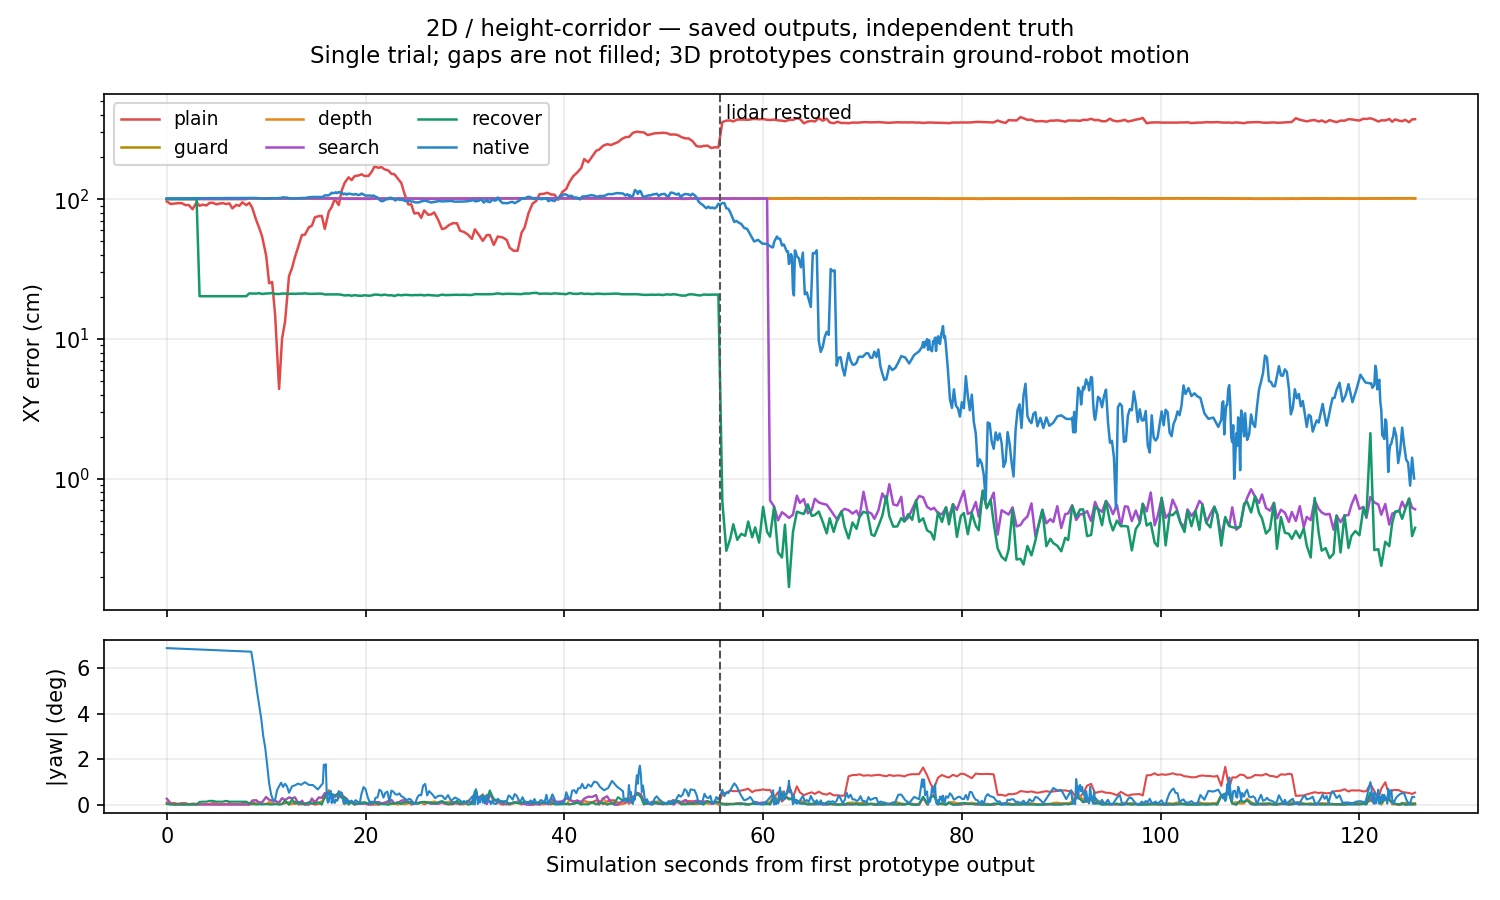

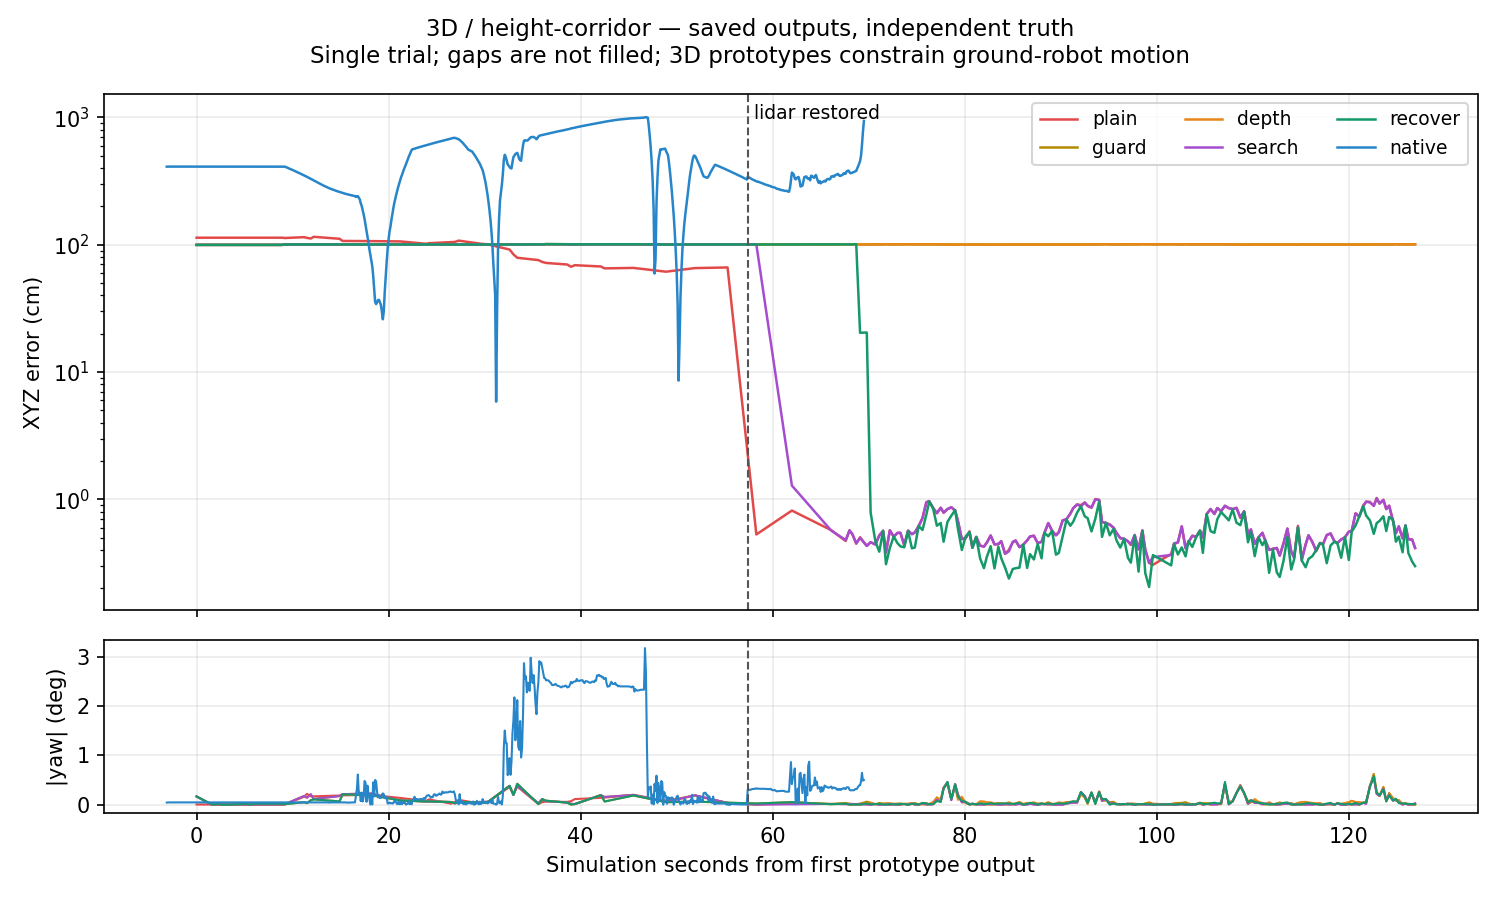

In [48]:
# 误差曲线由保存输出与独立真值计算；没有对缺失输出补点。
summary = read(ANALYSIS / 'calibrated-summary.json')
for dimension in ('2d', '3d'):
    plot = ANALYSIS / f'calibrated-{dimension}-height-corridor-errors.png'
    row = next(r for r in summary['conditions'] if r['dimension'] == dimension and r['scene'] == 'height-corridor')
    assert hashlib.sha256(plot.read_bytes()).hexdigest() == row['plot_sha256']
    display(Image(filename=str(plot)))

In [49]:
# 现场入口：仅手动启用本格才启动新场景；39查看，50十组，51–55同输入细化。
RUN_LIVE = False
RUN_REFINEMENT = False
live_command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
                str(REPO / 'demo/record-probes.ps1'), '-Dimension', '2D', '-Scene', 'height-corridor']
refine_command = ['powershell.exe', '-NoProfile', '-ExecutionPolicy', 'Bypass', '-File',
                  str(REPO / 'demo/refine-probes.ps1'), '-All']
print('新计算和实录:', subprocess.list2cmdline(live_command))
print('封存输入重新推理，结果回放:', subprocess.list2cmdline(refine_command))
if RUN_LIVE:
    subprocess.Popen(live_command)
if RUN_REFINEMENT:
    subprocess.Popen(refine_command)

新计算和实录: powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\record-probes.ps1 -Dimension 2D -Scene height-corridor
封存输入重新推理，结果回放: powershell.exe -NoProfile -ExecutionPolicy Bypass -File D:\workspace\be2\slam_learning_updated\demo\refine-probes.ps1 -All
